In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import pandas as pd
import datetime as dt

from matplotlib.pyplot import grid
from sklearn import model_selection
import seaborn as sns

In [2]:
df = pd.read_csv(r"C:\Users\Gabri\PycharmProjects\Bank-fraud-predict\data\transactions.csv")
df.head()

,transaction_id,user_id,account_age_days,total_transactions_user,avg_amount_user,amount,country,bin_country,channel,merchant_category,promo_used,avs_match,cvv_result,three_ds_flag,transaction_time,shipping_distance_km,is_fraud
0,1,1,141,47,147.93,84.75,FR,FR,web,travel,0,1,1,1,2024-01-06T04:09:39Z,370.95,0
1,2,1,141,47,147.93,107.90,FR,FR,web,travel,0,0,0,0,2024-01-09T20:13:47Z,149.62,0
2,3,1,141,47,147.93,92.36,FR,FR,app,travel,1,1,1,1,2024-01-12T06:20:11Z,164.08,0
3,4,1,141,47,147.93,112.47,FR,FR,web,fashion,0,1,1,1,2024-01-15T17:00:04Z,397.40,0
4,5,1,141,47,147.93,132.91,FR,US,web,electronics,0,1,1,1,2024-01-17T01:27:31Z,935.28,0


**Sample**
-

In [3]:
df.shape

(299695, 17)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 299695 entries, 0 to 299694
Data columns (total 17 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   transaction_id           299695 non-null  int64  
 1   user_id                  299695 non-null  int64  
 2   account_age_days         299695 non-null  int64  
 3   total_transactions_user  299695 non-null  int64  
 4   avg_amount_user          299695 non-null  float64
 5   amount                   299695 non-null  float64
 6   country                  299695 non-null  str    
 7   bin_country              299695 non-null  str    
 8   channel                  299695 non-null  str    
 9   merchant_category        299695 non-null  str    
 10  promo_used               299695 non-null  int64  
 11  avs_match                299695 non-null  int64  
 12  cvv_result               299695 non-null  int64  
 13  three_ds_flag            299695 non-null  int64  
 14  transaction_tim

In [5]:
df['transaction_time'].sort_values().unique()

<ArrowStringArray>
['2024-01-01T00:04:37Z', '2024-01-01T00:06:18Z', '2024-01-01T00:10:27Z',
 '2024-01-01T00:11:09Z', '2024-01-01T00:12:24Z', '2024-01-01T00:12:29Z',
 '2024-01-01T00:13:14Z', '2024-01-01T00:13:45Z', '2024-01-01T00:15:31Z',
 '2024-01-01T00:17:49Z',
 ...
 '2024-10-31T23:49:05Z', '2024-10-31T23:49:06Z', '2024-10-31T23:49:15Z',
 '2024-10-31T23:49:32Z', '2024-10-31T23:49:37Z', '2024-10-31T23:51:57Z',
 '2024-10-31T23:55:29Z', '2024-10-31T23:55:45Z', '2024-10-31T23:56:54Z',
 '2024-10-31T23:58:19Z']
Length: 297975, dtype: str

Tratando coluna com data e hora

In [6]:
df['transaction_datetime'] = df.transaction_time
df['transaction_datetime'] = pd.to_datetime(df['transaction_datetime'])
df.drop(['transaction_time'], axis=1, inplace=True)
df['transaction_date'] = df['transaction_datetime'].dt.date
df['transaction_time'] = df['transaction_datetime'].dt.time
df.head()

,transaction_id,user_id,account_age_days,total_transactions_user,avg_amount_user,amount,country,bin_country,channel,merchant_category,promo_used,avs_match,cvv_result,three_ds_flag,shipping_distance_km,is_fraud,transaction_datetime,transaction_date,transaction_time
0,1,1,141,47,147.93,84.75,FR,FR,web,travel,0,1,1,1,370.95,0,2024-01-06 04:09:39+00:00,2024-01-06,04:09:39
1,2,1,141,47,147.93,107.90,FR,FR,web,travel,0,0,0,0,149.62,0,2024-01-09 20:13:47+00:00,2024-01-09,20:13:47
2,3,1,141,47,147.93,92.36,FR,FR,app,travel,1,1,1,1,164.08,0,2024-01-12 06:20:11+00:00,2024-01-12,06:20:11
3,4,1,141,47,147.93,112.47,FR,FR,web,fashion,0,1,1,1,397.40,0,2024-01-15 17:00:04+00:00,2024-01-15,17:00:04
4,5,1,141,47,147.93,132.91,FR,US,web,electronics,0,1,1,1,935.28,0,2024-01-17 01:27:31+00:00,2024-01-17,01:27:31


**Criando OOT**

Vou usar cerca de 10% da base para validação

In [7]:
df['transaction_date'].max()

datetime.date(2024, 10, 31)

In [8]:
df[df['transaction_date'] > dt.date(2024, 10, 28)].shape[0]

2964

In [9]:
oot = df[df['transaction_date'] > dt.date(2024, 10, 28)]
oot.head()

,transaction_id,user_id,account_age_days,total_transactions_user,avg_amount_user,amount,country,bin_country,channel,merchant_category,promo_used,avs_match,cvv_result,three_ds_flag,shipping_distance_km,is_fraud,transaction_datetime,transaction_date,transaction_time
103,104,2,1598,57,78.39,93.38,US,US,web,travel,0,1,1,1,389.69,0,2024-10-29 19:22:08+00:00,2024-10-29,19:22:08
255,256,5,497,53,71.23,58.71,PL,PL,app,electronics,0,0,0,0,80.16,0,2024-10-30 12:50:12+00:00,2024-10-30,12:50:12
295,296,6,1296,40,71.23,39.27,FR,FR,web,gaming,0,1,1,1,246.38,0,2024-10-29 16:22:09+00:00,2024-10-29,16:22:09
388,389,8,530,43,193.92,95.23,IT,IT,web,gaming,1,1,1,0,491.55,0,2024-10-30 22:41:59+00:00,2024-10-30,22:41:59
600,601,12,1377,51,56.50,41.69,RO,RO,web,travel,0,0,0,0,335.65,0,2024-10-30 05:07:17+00:00,2024-10-30,05:07:17


In [10]:
df_train = df[df['transaction_date'] < dt.date(2024, 10, 29)]
df_train.shape

(296731, 19)

In [11]:
features = df_train.columns.drop(['is_fraud','transaction_id','user_id'])
target = 'is_fraud'
features

Index(['account_age_days', 'total_transactions_user', 'avg_amount_user',
       'amount', 'country', 'bin_country', 'channel', 'merchant_category',
       'promo_used', 'avs_match', 'cvv_result', 'three_ds_flag',
       'shipping_distance_km', 'transaction_datetime', 'transaction_date',
       'transaction_time'],
      dtype='str')

In [12]:
X, y = df_train[features], df_train[target]
X.head()

,account_age_days,total_transactions_user,avg_amount_user,amount,country,bin_country,channel,merchant_category,promo_used,avs_match,cvv_result,three_ds_flag,shipping_distance_km,transaction_datetime,transaction_date,transaction_time
0,141,47,147.93,84.75,FR,FR,web,travel,0,1,1,1,370.95,2024-01-06 04:09:39+00:00,2024-01-06,04:09:39
1,141,47,147.93,107.90,FR,FR,web,travel,0,0,0,0,149.62,2024-01-09 20:13:47+00:00,2024-01-09,20:13:47
2,141,47,147.93,92.36,FR,FR,app,travel,1,1,1,1,164.08,2024-01-12 06:20:11+00:00,2024-01-12,06:20:11
3,141,47,147.93,112.47,FR,FR,web,fashion,0,1,1,1,397.40,2024-01-15 17:00:04+00:00,2024-01-15,17:00:04
4,141,47,147.93,132.91,FR,US,web,electronics,0,1,1,1,935.28,2024-01-17 01:27:31+00:00,2024-01-17,01:27:31


In [13]:
y.head()

0    0
1    0
2    0
3    0
4    0
Name: is_fraud, dtype: int64

Dropando coluna com id do cliente

In [14]:
X_train, X_test, y_train, y_test = model_selection.train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [15]:
print("Shape of train features dataset: ",X_train.shape[0])
print("Shape of train target dataset: ",y_train.shape[0])
print("Shape of test features dataset: ",X_test.shape[0])
print("Shape of test target dataset: ",y_test.shape[0])

Shape of train features dataset:  237384
Shape of train target dataset:  237384
Shape of test features dataset:  59347
Shape of test target dataset:  59347


In [16]:
print('Taxa da variável resposta General', y.mean())
print('Taxa da variável resposta Train', y_train.mean())
print('Taxa da variável resposta Test', y_test.mean())

Taxa da variável resposta General 0.022009833822553088
Taxa da variável resposta Train 0.022010750513935227
Taxa da variável resposta Test 0.022006167118809712


**Explore**
-

In [17]:
X_train.isna().sum().sort_values(ascending=False)

account_age_days           0
total_transactions_user    0
avg_amount_user            0
amount                     0
country                    0
bin_country                0
channel                    0
merchant_category          0
promo_used                 0
avs_match                  0
cvv_result                 0
three_ds_flag              0
shipping_distance_km       0
transaction_datetime       0
transaction_date           0
transaction_time           0
dtype: int64

Criando um dataframe com todas as colunas de treino

In [18]:
df_analysis = pd.concat([X_train, y_train], axis=1).copy()
df_analysis['is_fraud'] = pd.to_numeric(df_analysis['is_fraud'])
df_analysis.head()

,account_age_days,total_transactions_user,avg_amount_user,amount,country,bin_country,channel,merchant_category,promo_used,avs_match,cvv_result,three_ds_flag,shipping_distance_km,transaction_datetime,transaction_date,transaction_time,is_fraud
162213,1045,51,259.33,498.39,TR,TR,app,gaming,0,1,1,0,388.29,2024-09-01 16:05:31+00:00,2024-09-01,16:05:31,0
23514,344,53,19.78,23.36,IT,IT,app,grocery,0,1,1,1,440.89,2024-10-02 20:59:35+00:00,2024-10-02,20:59:35,0
97883,556,43,119.77,45.90,ES,ES,web,fashion,1,1,1,1,163.22,2024-04-10 23:07:49+00:00,2024-04-10,23:07:49,0
89375,307,55,343.93,201.40,US,US,web,electronics,1,1,1,1,46.59,2024-06-29 09:42:58+00:00,2024-06-29,09:42:58,0
233780,1137,50,31.91,46.66,DE,DE,app,grocery,0,1,1,1,361.09,2024-09-11 15:29:07+00:00,2024-09-11,15:29:07,0


Separando features numéricas e categóricas

In [19]:
num_features = X_train.select_dtypes('number').columns.tolist()
cat_features = X_train.select_dtypes("str").columns.tolist()
num_features

['account_age_days',
 'total_transactions_user',
 'avg_amount_user',
 'amount',
 'promo_used',
 'avs_match',
 'cvv_result',
 'three_ds_flag',
 'shipping_distance_km']

In [20]:
cat_features

['country', 'bin_country', 'channel', 'merchant_category']

In [21]:
df_analysis[num_features].describe()

,account_age_days,total_transactions_user,avg_amount_user,amount,promo_used,avs_match,cvv_result,three_ds_flag,shipping_distance_km
count,237384.000000,237384.000000,237384.000000,237384.000000,237384.000000,237384.000000,237384.000000,237384.000000,237384.000000
mean,973.491297,50.673221,147.888686,176.622488,0.153574,0.838174,0.872439,0.784796,356.955198
std,524.942365,5.972022,199.224210,303.785571,0.360541,0.368292,0.333601,0.410965,427.154721
min,1.000000,40.000000,3.520000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,518.000000,46.000000,46.190000,42.080000,0.000000,1.000000,1.000000,1.000000,136.697500
50%,974.000000,51.000000,90.060000,90.030000,0.000000,1.000000,1.000000,1.000000,272.950000
75%,1425.000000,56.000000,173.450000,190.872500,0.000000,1.000000,1.000000,1.000000,409.380000
max,1890.000000,60.000000,4565.290000,16979.920000,1.000000,1.000000,1.000000,1.000000,3748.560000


In [41]:
for feature in cat_features:
    print(feature)
    print("-"*40)
    print(f"{df_analysis[feature].nunique()} unique values: ")
    percent = (df_analysis[feature].value_counts(normalize=True) * 100)
    print(percent.apply(lambda x:f"{x:.2f}%"))
    print()

country
----------------------------------------
10 unique values: 
country
US    10.79%
GB    10.16%
FR    10.10%
NL    10.06%
TR    10.05%
PL    10.00%
RO     9.84%
DE     9.72%
ES     9.70%
IT     9.58%
Name: proportion, dtype: str

bin_country
----------------------------------------
10 unique values: 
bin_country
US    10.73%
GB    10.16%
FR    10.09%
NL    10.07%
TR    10.02%
PL    10.02%
RO     9.83%
ES     9.74%
DE     9.72%
IT     9.61%
Name: proportion, dtype: str

channel
----------------------------------------
2 unique values: 
channel
web    50.77%
app    49.23%
Name: proportion, dtype: str

merchant_category
----------------------------------------
5 unique values: 
merchant_category
electronics    20.08%
grocery        20.02%
travel         19.98%
gaming         19.97%
fashion        19.95%
Name: proportion, dtype: str



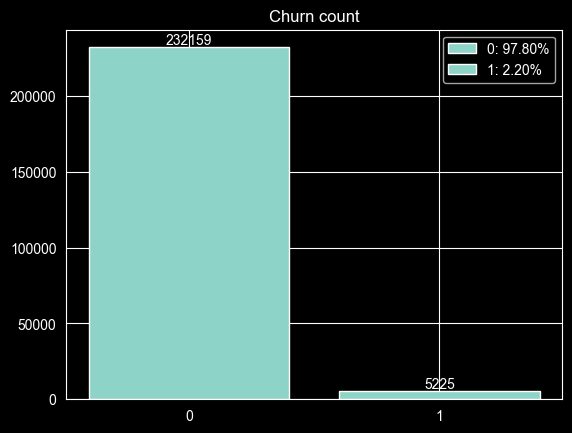

In [23]:
count = df_analysis[target].value_counts()
percent_count = df_analysis[target].value_counts(normalize=True) * 100
legend_labels = [f'{idx}: {percent_count[idx]:.2f}%' for idx in count.index]

plt.title("Churn count")

bars = plt.bar(count.index.astype(str), count.values, align='center')
plt.bar_label(bars)
plt.legend(bars, legend_labels)
plt.show()

O dataset se mostra muito desbalanceado

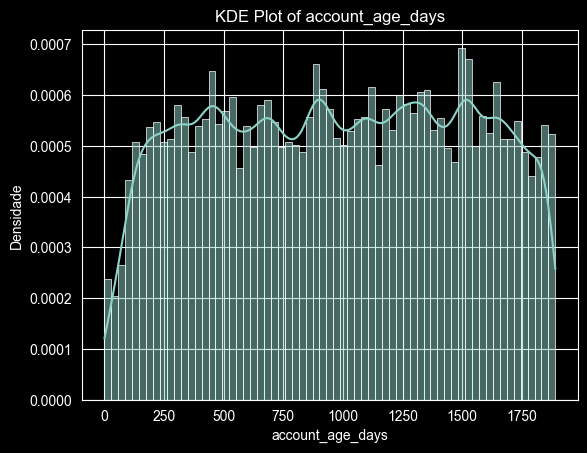

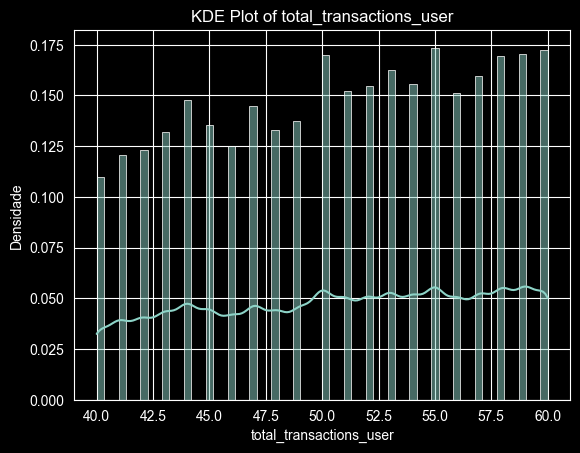

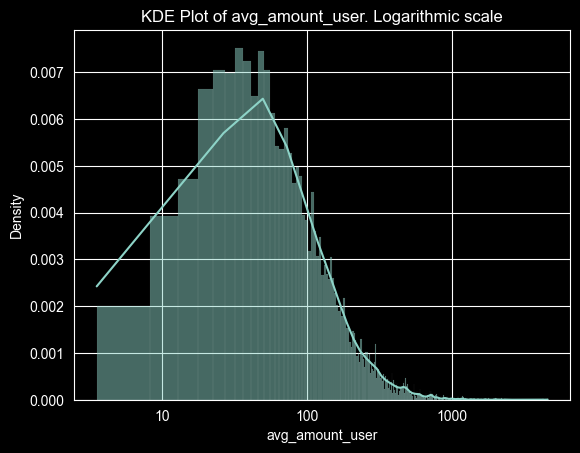

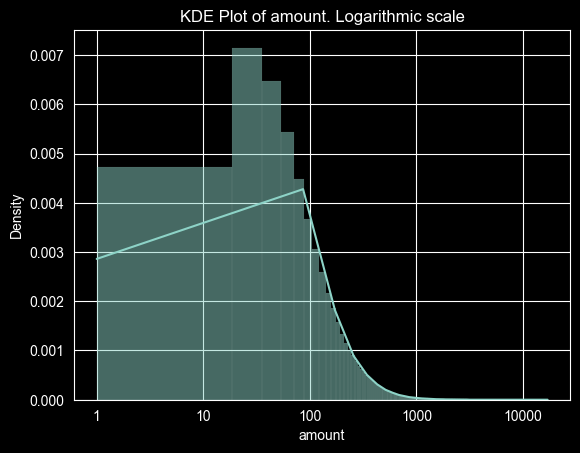

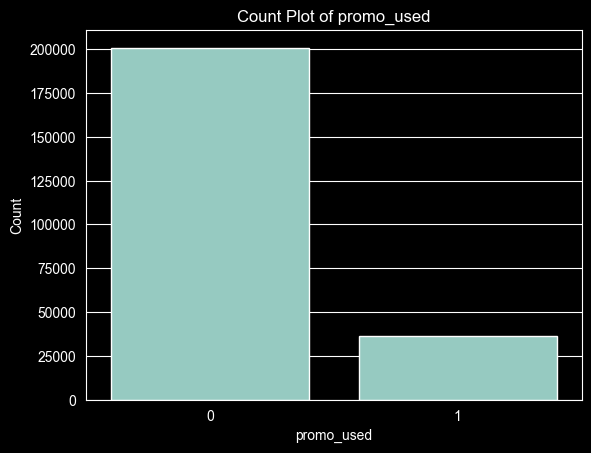

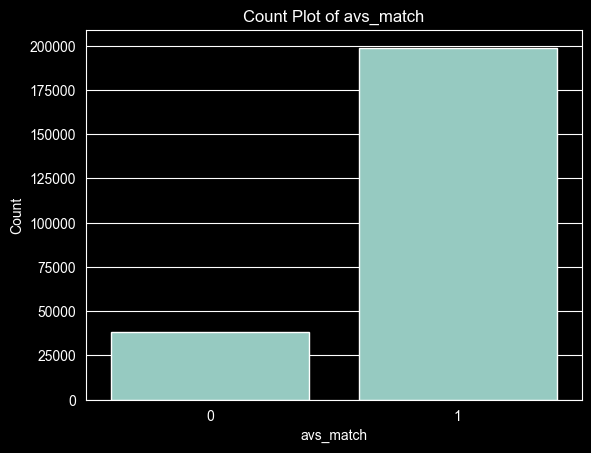

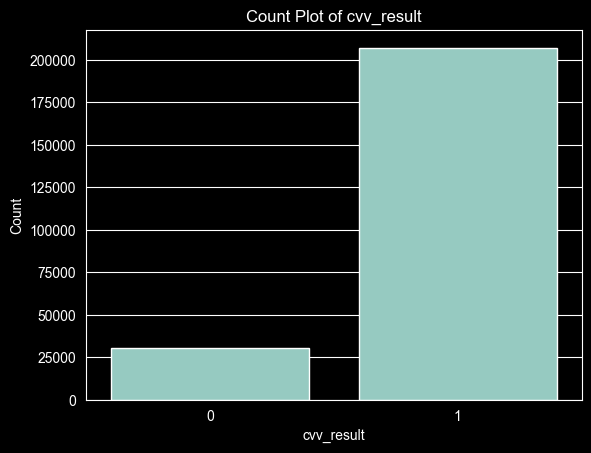

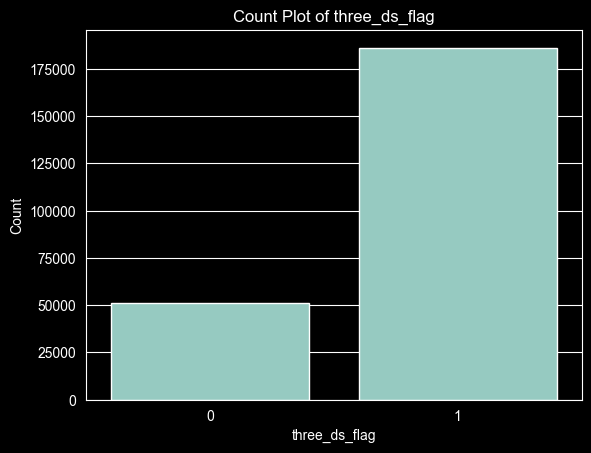

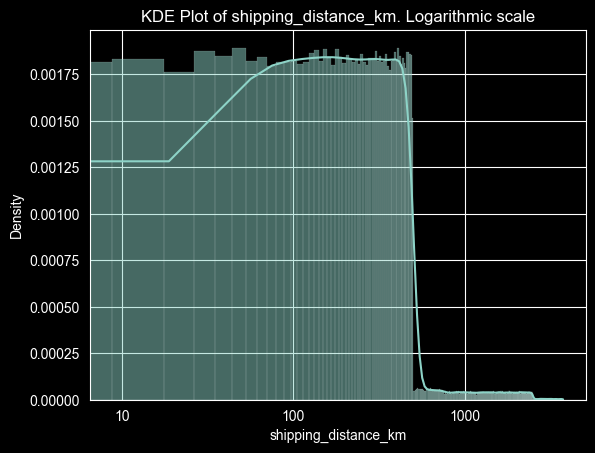

In [34]:
for feature in num_features:
    if feature in ['amount','avg_amount_user','shipping_distance_km']:
        sns.histplot(data=df_analysis, x=feature, kde=True, stat='density', common_norm=True)
        plt.xscale('log')
        plt.gca().xaxis.set_major_formatter(ticker.ScalarFormatter())
        plt.title(f'KDE Plot of {feature}. Logarithmic scale')
        plt.show()
    elif feature in ['promo_used','avs_match',"cvv_result",'three_ds_flag']:
        sns.countplot(data=df_analysis, x=feature)
        plt.ylabel('Count')
        plt.title(f'Count Plot of {feature}')
        plt.show()

    else:
        sns.histplot(data=df_analysis, x=feature, kde=True, stat='density',  common_norm=True)
        plt.ylabel('Densidade')
        plt.title(f'KDE Plot of {feature}')
        plt.show()


Distribuição das variáveis numéricas

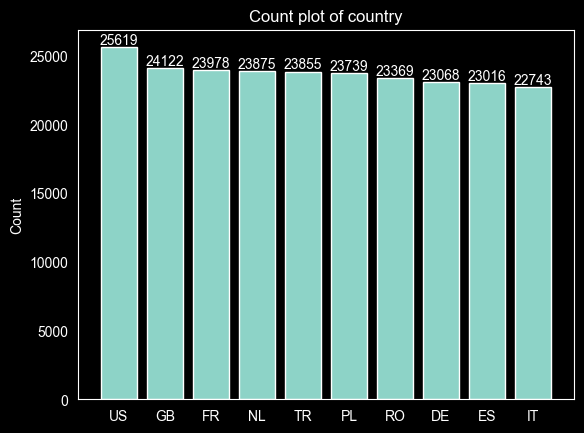

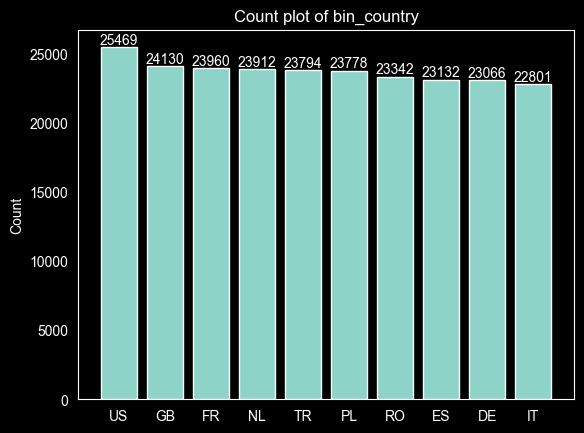

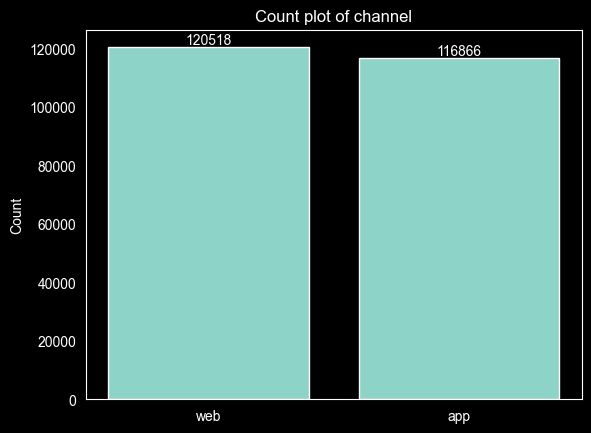

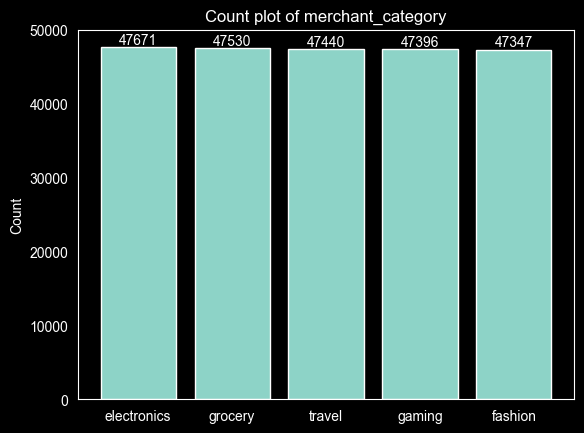

In [55]:
for feature in cat_features:
        count = df_analysis[feature].value_counts()
        bars = plt.bar(count.index.astype(str), count.values, align='center')
        plt.bar_label(bars)
        plt.grid(False)
        plt.ylabel("Count")
        plt.title(f'Count plot of {feature}')
        plt.show()

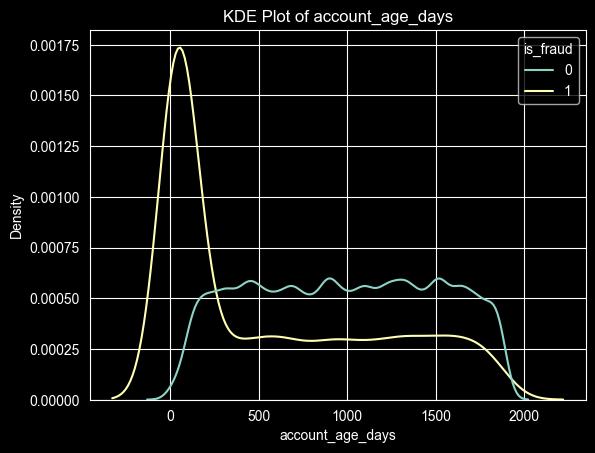

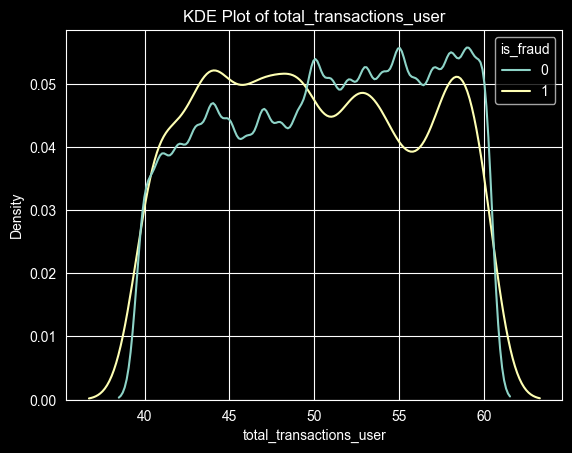

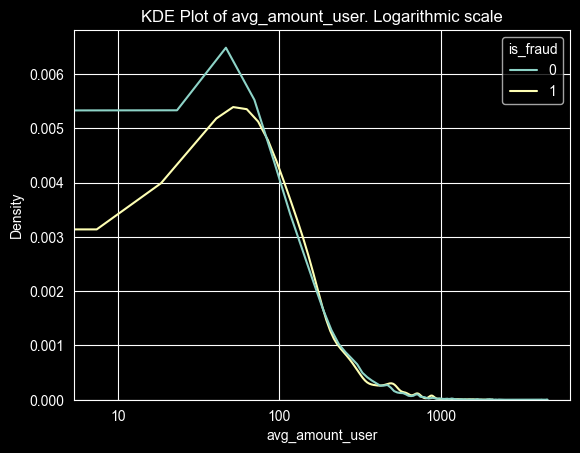

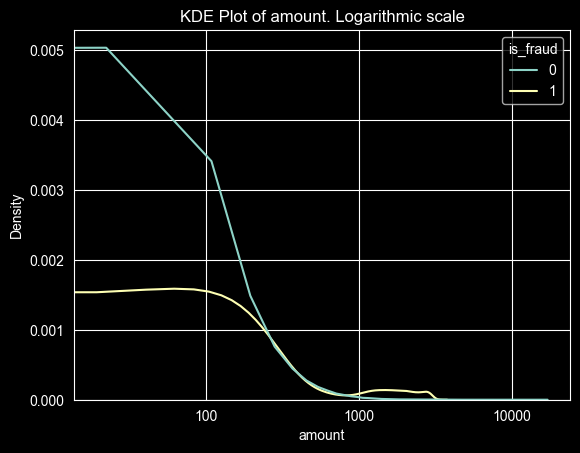

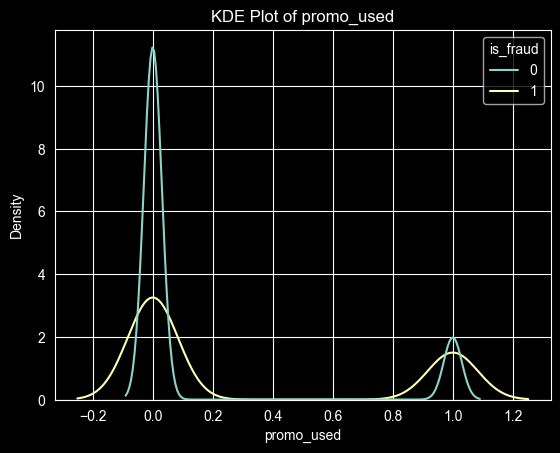

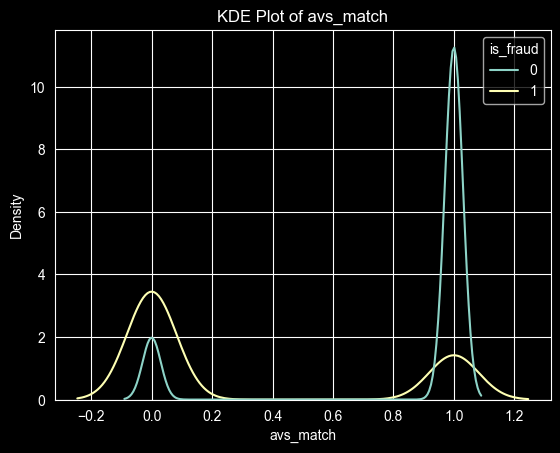

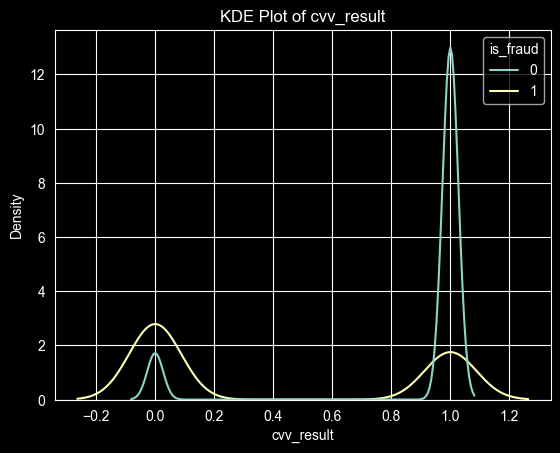

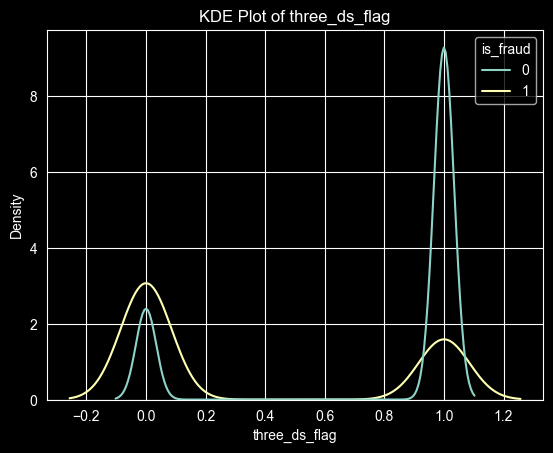

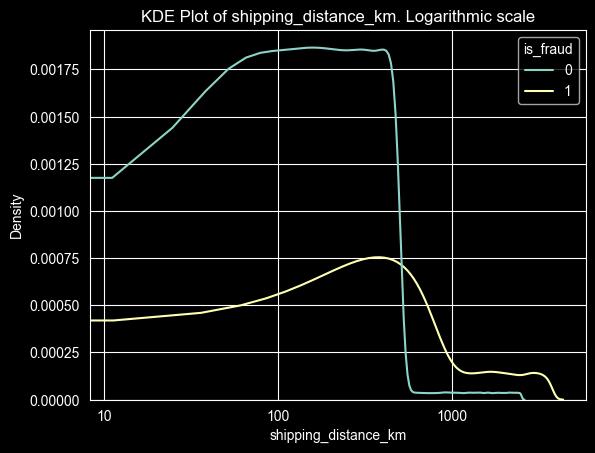

In [28]:
for feature in num_features:

    if feature in ['amount','avg_amount_user','shipping_distance_km']:
        sns.kdeplot(data=df_analysis, x=feature, hue=target, common_norm=False)
        plt.xscale('log')
        plt.gca().xaxis.set_major_formatter(ticker.ScalarFormatter())
        plt.title(f'KDE Plot of {feature}. Logarithmic scale')
    else:
        sns.kdeplot(data=df_analysis, x=feature, hue=target, common_norm=False)
        plt.title(f'KDE Plot of {feature}')
    plt.show()

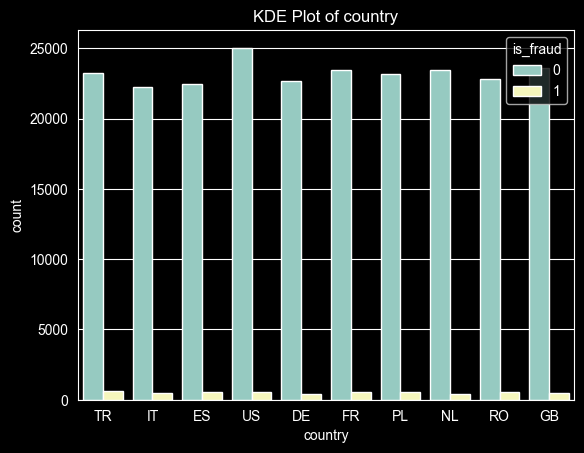

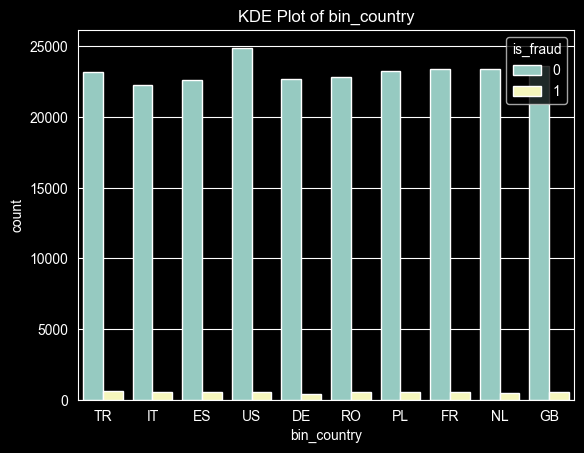

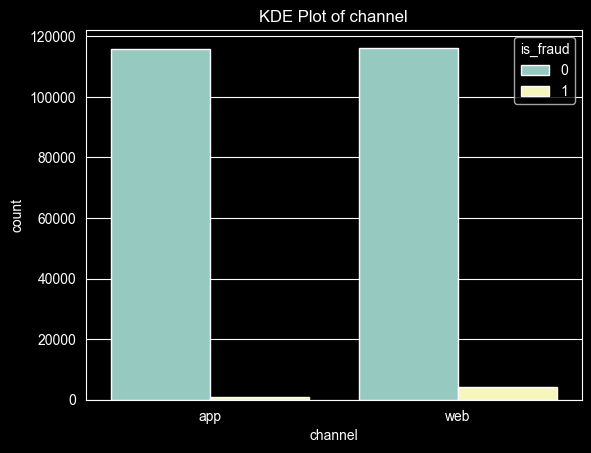

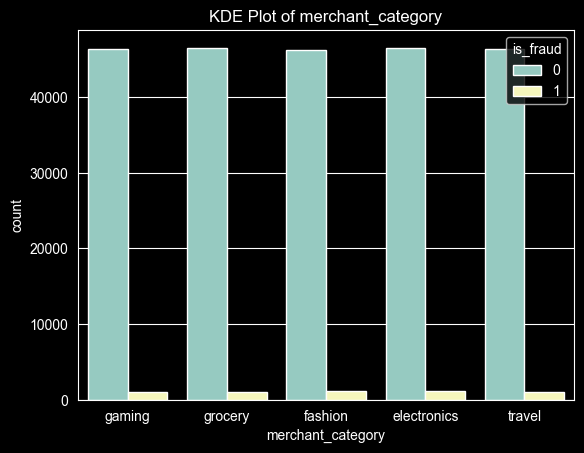

In [47]:
for feature in cat_features:
        sns.countplot(data=df_analysis, x=feature, hue=target)
        plt.title(f'KDE Plot of {feature}')
        plt.show()

In [25]:
summarie = df_analysis.select_dtypes(include='number').groupby(by=target).agg(['mean','median']).T
summarie

is_fraud                                 0            1
account_age_days        mean    982.839993   558.106794
                        median  986.000000   222.000000
total_transactions_user mean     50.688571    49.991196
                        median   51.000000    50.000000
avg_amount_user         mean    147.911253   146.886010
                        median   90.060000    88.060000
amount                  mean    167.595096   577.730679
                        median   89.890000   102.920000
promo_used              mean      0.149932     0.315407
                        median    0.000000     0.000000
avs_match               mean      0.850486     0.291100
                        median    1.000000     0.000000
cvv_result              mean      0.883390     0.385837
                        median    1.000000     0.000000
three_ds_flag           mean      0.794783     0.341053
                        median    1.000000     0.000000
shipping_distance_km    mean    339.658418  1125.491684
                        median  269.490000   627.410000

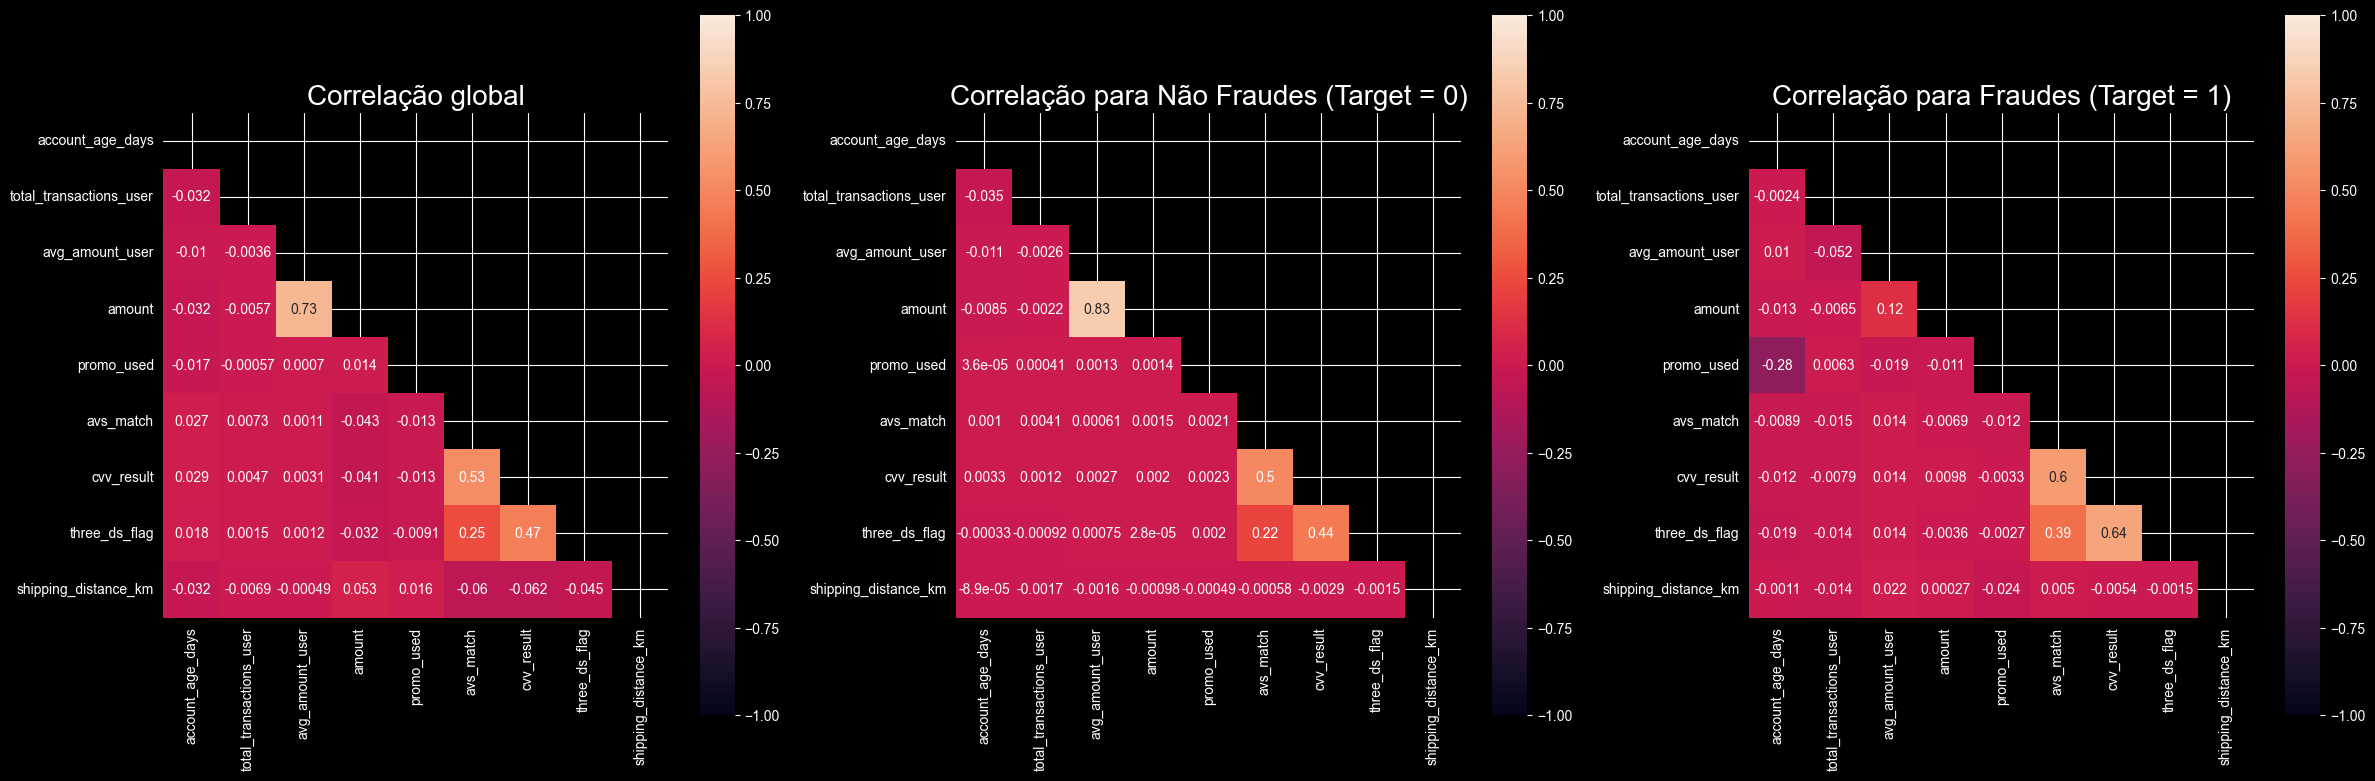

In [26]:
corr_global = df_analysis[num_features].corr()
corr_0 = df_analysis[df_analysis[target] == 0][num_features].corr()
corr_1 = df_analysis[df_analysis[target] == 1][num_features].corr()

fig , axes = plt.subplots(1, 3, figsize=(24, 8))

mask = np.triu(np.ones_like(df_analysis[num_features].corr(), dtype=bool))

sns.heatmap(corr_global, mask=mask, square=True, vmin=-1, vmax=1, annot=True, ax=axes[0])
axes[0].set_title("Correlação global", fontsize=20)

sns.heatmap(corr_0, mask=mask, square=True, vmin=-1, vmax=1, annot=True, ax=axes[1])
axes[1].set_title("Correlação para Não Fraudes (Target = 0)", fontsize=20)

sns.heatmap(corr_1, mask=mask, square=True, vmin=-1, vmax=1, annot=True, ax=axes[2])
axes[2].set_title("Correlação para Fraudes (Target = 1)", fontsize=20)

plt.tight_layout()
plt.show()